<a href="https://colab.research.google.com/github/Farrukh776/agentic-ai-hands-on/blob/main/contrastive_learning/contrastive_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab: Contrastive Learning from Scratch

In this lab you will train a neural network to produce **embeddings without using any labels**,
using contrastive learning. Follow the lab manual alongside this notebook.

**Runtime:** a CPU runtime is enough (Runtime → Change runtime type → CPU). Total run time: a few minutes.

## Task 1 — Setup and data

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.manifold import TSNE

torch.manual_seed(0)
np.random.seed(0)

# 1,797 handwritten digits, each an 8x8 grey-scale image (values 0-16)
X, y = load_digits(return_X_y=True)
X = (X / 16.0).astype(np.float32).reshape(-1, 1, 8, 8)   # scale to [0, 1]

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
Xtr, Xte = torch.tensor(Xtr), torch.tensor(Xte)
print("Training images:", Xtr.shape, "  Test images:", Xte.shape)

Training images: torch.Size([1257, 1, 8, 8])   Test images: torch.Size([540, 1, 8, 8])


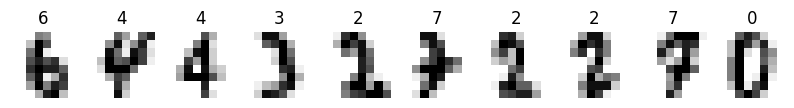

In [2]:
fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for i, ax in enumerate(axes):
    ax.imshow(Xtr[i, 0], cmap="gray_r"); ax.set_title(int(ytr[i])); ax.axis("off")
plt.show()

## Task 2 — Augmentation: two views of the same image

In [3]:
def augment(x, max_shift=2, noise=0.1):
    """Randomly shift each image by up to `max_shift` pixels and add a little noise."""
    n = x.shape[0]
    padded = F.pad(x, (max_shift,) * 4)              # add a border of zeros
    out = torch.empty_like(x)
    dx = torch.randint(-max_shift, max_shift + 1, (n,))
    dy = torch.randint(-max_shift, max_shift + 1, (n,))
    for i in range(n):
        r, c = max_shift + dy[i], max_shift + dx[i]
        out[i] = padded[i, :, r:r + 8, c:c + 8]       # crop an 8x8 window at a shifted place
    out = out + noise * torch.randn_like(out)
    return out.clamp(0, 1)

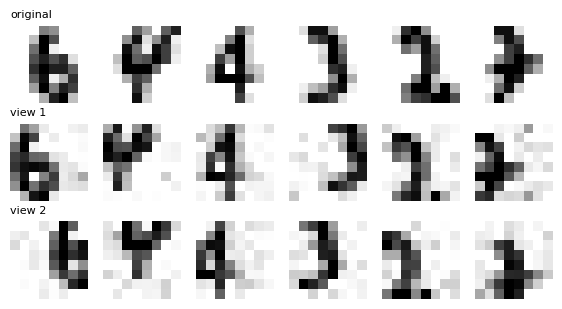

In [4]:
x = Xtr[:6]
v1, v2 = augment(x), augment(x)
fig, axes = plt.subplots(3, 6, figsize=(7, 3.6))
for i in range(6):
    for row, img, name in [(0, x, "original"), (1, v1, "view 1"), (2, v2, "view 2")]:
        axes[row, i].imshow(img[i, 0], cmap="gray_r"); axes[row, i].axis("off")
        if i == 0: axes[row, i].set_title(name, fontsize=8, loc="left")
plt.show()

Your Turn: my choice is max_shift = 2.
With max_shift = 0 the two views differ only by noise, so the digit never moves and the model has nothing to learn about shifts. With max_shift = 3 the digit is pushed so far that parts of it fall off the 8x8 image (for example the 6 in the first column is mostly cut off in view 2), so the two views stop being "the same thing". max_shift = 2 changes the pixels a lot but every digit is still recognisable.

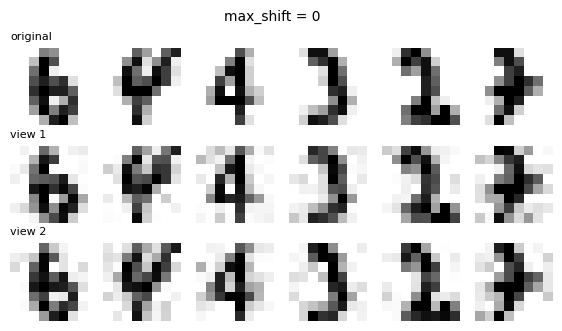

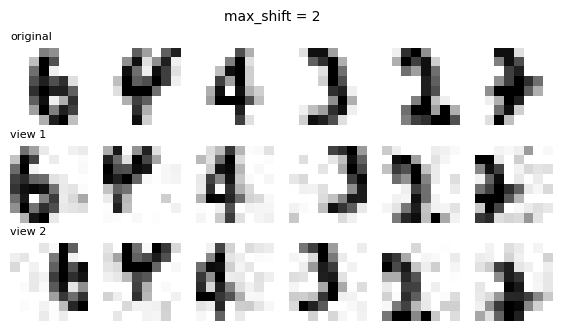

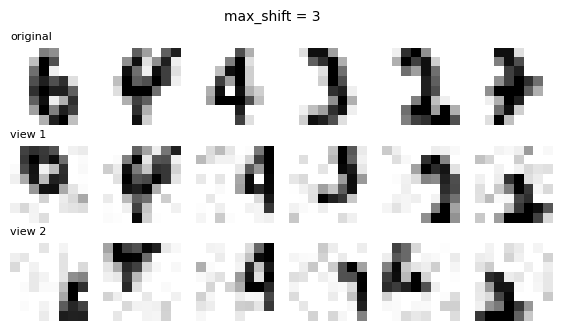

In [13]:
# Compare max_shift = 0, 2 (default) and 3
x = Xtr[:6]
for ms in [0, 2, 3]:
    torch.manual_seed(0)
    v1, v2 = augment(x, max_shift=ms), augment(x, max_shift=ms)
    fig, axes = plt.subplots(3, 6, figsize=(7, 3.6))
    fig.suptitle(f"max_shift = {ms}", fontsize=10)
    for i in range(6):
        for row, img, name in [(0, x, "original"), (1, v1, "view 1"), (2, v2, "view 2")]:
            axes[row, i].imshow(img[i, 0], cmap="gray_r"); axes[row, i].axis("off")
            if i == 0: axes[row, i].set_title(name, fontsize=8, loc="left")
    plt.show()

## Task 3 — The encoder

In [5]:
class Encoder(nn.Module):
    """Maps an 8x8 image to a 32-dimensional embedding of length 1."""
    def __init__(self, dim=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 256), nn.ReLU(),
            nn.Linear(256, 256), nn.ReLU(),
            nn.Linear(256, dim))
    def forward(self, x):
        return F.normalize(self.net(x), dim=1)   # unit length, so dot product = cosine similarity

enc = Encoder()
print(enc(Xtr[:4]).shape)   # 4 images -> 4 embeddings of size 32

torch.Size([4, 32])


## Task 4 — The contrastive (InfoNCE) loss

In [6]:
def info_nce(z1, z2, tau=0.1):
    """
    z1[i] and z2[i] are embeddings of two views of image i (a positive pair).
    Every other embedding in the batch is a negative for image i.
    """
    n = z1.shape[0]
    z = torch.cat([z1, z2])                 # 2n embeddings
    sim = z @ z.T / tau                     # cosine similarity of every pair, divided by temperature
    sim.fill_diagonal_(-1e9)                # an embedding is not compared with itself
    # the positive for row i is row i+n (and for row i+n it is row i)
    target = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)])
    return F.cross_entropy(sim, target)

In [7]:
# Sanity check: an untrained encoder cannot tell positives from negatives,
# so the loss should be close to log(2n - 1)
xb = Xtr[:256]
with torch.no_grad():
    loss0 = info_nce(enc(augment(xb)), enc(augment(xb)))
print(f"Initial loss: {loss0.item():.2f}    log(2n-1) = {np.log(2*256 - 1):.2f}")

Initial loss: 6.24    log(2n-1) = 6.24


## Task 5 — Train without labels

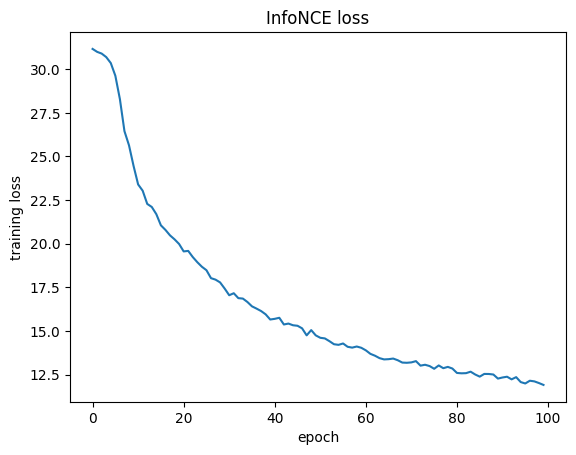

In [8]:
def train(loss_fn=info_nce, tau=0.1, epochs=100, batch_size=256, aug=augment):
    torch.manual_seed(0)
    enc = Encoder()
    opt = torch.optim.Adam(enc.parameters(), lr=1e-3)
    history = []
    for epoch in range(epochs):
        perm = torch.randperm(len(Xtr))
        total = 0.0
        for i in range(0, len(Xtr), batch_size):
            xb = Xtr[perm[i:i + batch_size]]        # note: labels are never used
            loss = loss_fn(enc(aug(xb)), enc(aug(xb)), tau)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item()
        history.append(total)
    return enc, history

enc, history = train()
plt.plot(history); plt.xlabel("epoch"); plt.ylabel("training loss"); plt.title("InfoNCE loss"); plt.show()

## Task 6 — Evaluate the embeddings

In [9]:
def embed(model, x):
    with torch.no_grad():
        return model(x).numpy()

raw = lambda x: x.reshape(len(x), -1).numpy()     # baseline: the 64 raw pixel values
untrained = Encoder()                              # baseline: random weights

# (a) Are positives close and negatives far?
def pos_neg_similarity(model):
    with torch.no_grad():
        z1, z2 = model(augment(Xte)), model(augment(Xte))
        S = z1 @ z2.T
        pos = S.diag().mean().item()
        neg = ((S.sum() - S.diag().sum()) / (S.numel() - len(S))).item()
    return pos, neg

for name, m in [("untrained", untrained), ("trained", enc)]:
    p, n = pos_neg_similarity(m)
    print(f"{name:<10} positive pairs: {p:.2f}   negative pairs: {n:.2f}")

untrained  positive pairs: 0.89   negative pairs: 0.88
trained    positive pairs: 0.86   negative pairs: 0.01


In [10]:
# (b) Nearest-neighbour accuracy on clean and on shifted test images
torch.manual_seed(1)
Xte_shifted = augment(Xte, max_shift=2, noise=0.0)

def knn_accuracy(features, x_test, k=5):
    clf = KNeighborsClassifier(n_neighbors=k, metric="cosine").fit(features(Xtr), ytr)
    return clf.score(features(x_test), yte)

print(f"{'features':<14}{'clean test':>12}{'shifted test':>14}")
for name, f in [("raw pixels", raw),
                ("untrained", lambda x: embed(untrained, x)),
                ("contrastive", lambda x: embed(enc, x))]:
    print(f"{name:<14}{knn_accuracy(f, Xte):>12.3f}{knn_accuracy(f, Xte_shifted):>14.3f}")

features        clean test  shifted test
raw pixels           0.978         0.270
untrained            0.952         0.200
contrastive          0.937         0.894


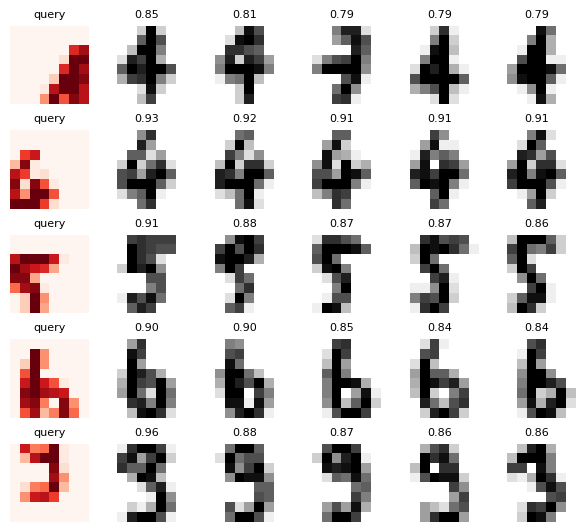

In [11]:
# (c) Retrieval: for a few query images, show the 5 most similar training images
Ztr, Zq = embed(enc, Xtr), embed(enc, Xte_shifted[:5])
fig, axes = plt.subplots(5, 6, figsize=(6, 5.4))
for r in range(5):
    sims = Ztr @ Zq[r]                       # cosine similarity to every training image
    top = np.argsort(-sims)[:5]
    axes[r, 0].imshow(Xte_shifted[r, 0], cmap="Reds"); axes[r, 0].set_title("query", fontsize=8)
    for j, idx in enumerate(top):
        axes[r, j + 1].imshow(Xtr[idx, 0], cmap="gray_r"); axes[r, j + 1].set_title(f"{sims[idx]:.2f}", fontsize=8)
    for ax in axes[r]: ax.axis("off")
plt.tight_layout(); plt.show()

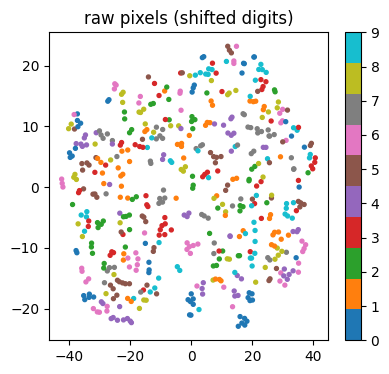

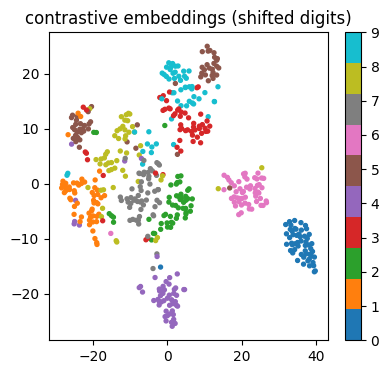

In [12]:
# (d) Picture the embedding space of the SHIFTED test images (labels only colour the points)
for name, f in [("raw pixels", raw), ("contrastive embeddings", lambda x: embed(enc, x))]:
    pts = TSNE(n_components=2, random_state=0).fit_transform(f(Xte_shifted))
    plt.figure(figsize=(4.5, 4))
    plt.scatter(pts[:, 0], pts[:, 1], c=yte, cmap="tab10", s=8)
    plt.colorbar(ticks=range(10)); plt.title(name + " (shifted digits)"); plt.show()

Top-1 retrieval mistakes: 67 / 540


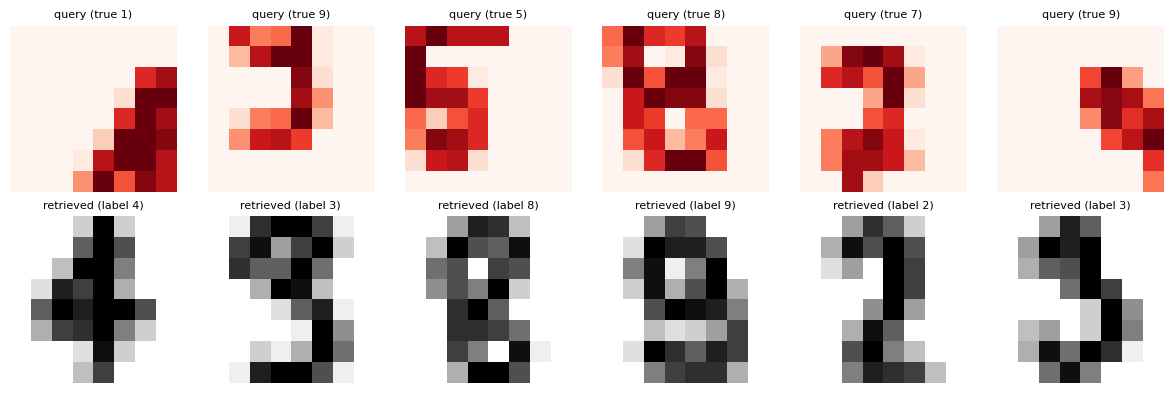

In [18]:
# Top-1 retrieval for all shifted test images; show mistakes with labels
Zte = embed(enc, Xte_shifted)
top1 = (Zte @ Ztr.T).argmax(axis=1)
wrong = np.where(ytr[top1] != yte)[0]
print(f"Top-1 retrieval mistakes: {len(wrong)} / {len(yte)}")

show = wrong[:6]
fig, axes = plt.subplots(2, len(show), figsize=(2 * len(show), 4))
for j, i in enumerate(show):
    axes[0, j].imshow(Xte_shifted[i, 0], cmap="Reds"); axes[0, j].set_title(f"query (true {yte[i]})", fontsize=8)
    axes[1, j].imshow(Xtr[top1[i], 0], cmap="gray_r");  axes[1, j].set_title(f"retrieved (label {ytr[top1[i]]})", fontsize=8)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

## Task 7 — Experiments

In [14]:
# (a) Remove the negatives: only pull the two views together
def no_negatives_loss(z1, z2, tau=0.1):
    return -(z1 * z2).sum(dim=1).mean()

enc_noneg, _ = train(loss_fn=no_negatives_loss, epochs=50)
p, n = pos_neg_similarity(enc_noneg)
print(f"positive pairs: {p:.4f}   negative pairs: {n:.4f}")
print(f"shifted-test accuracy: {knn_accuracy(lambda x: embed(enc_noneg, x), Xte_shifted):.3f}")

positive pairs: 1.0000   negative pairs: 1.0000
shifted-test accuracy: 0.156


In [15]:
# (b) Temperature, results are saved in a dictionary
tau_results = {}
for tau in [0.05, 0.1, 0.5, 1.0]:
    e, _ = train(tau=tau, epochs=50)
    tau_results[tau] = knn_accuracy(lambda x: embed(e, x), Xte_shifted)
    print(f"tau = {tau:<5} shifted-test accuracy: {tau_results[tau]:.3f}")

tau = 0.05  shifted-test accuracy: 0.856
tau = 0.1   shifted-test accuracy: 0.859
tau = 0.5   shifted-test accuracy: 0.769
tau = 1.0   shifted-test accuracy: 0.704


In [16]:
# (c) Change the augmentation: train with noise only (no shifting)
noise_only = lambda x: augment(x, max_shift=0, noise=0.1)
enc_noshift, _ = train(aug=noise_only, epochs=50)
print(f"clean-test accuracy:   {knn_accuracy(lambda x: embed(enc_noshift, x), Xte):.3f}")
print(f"shifted-test accuracy: {knn_accuracy(lambda x: embed(enc_noshift, x), Xte_shifted):.3f}")

clean-test accuracy:   0.967
shifted-test accuracy: 0.241


In [17]:
import pandas as pd

def both(f):
    return knn_accuracy(f, Xte), knn_accuracy(f, Xte_shifted)

f_raw    = raw
f_untr   = lambda x: embed(untrained, x)
f_contr  = lambda x: embed(enc, x)
f_noneg  = lambda x: embed(enc_noneg, x)
f_noshft = lambda x: embed(enc_noshift, x)

rows = []
for name, f in [("Raw pixels", f_raw), ("Untrained encoder", f_untr),
                ("Contrastive encoder (tau = 0.1)", f_contr)]:
    c, s = both(f); rows.append((name, round(c, 3), round(s, 3)))

rows.append(("No negatives", "-", round(knn_accuracy(f_noneg, Xte_shifted), 3)))
for tau in [0.05, 0.5, 1.0]:
    rows.append((f"tau = {tau}", "-", round(tau_results[tau], 3)))

c, s = both(f_noshft)
rows.append(("Noise-only augmentation", round(c, 3), round(s, 3)))

table1 = pd.DataFrame(rows, columns=["Experiment", "Clean-test accuracy", "Shifted-test accuracy"])
print("TABLE 1: Results"); display(table1)

sim_rows = []
for name, m in [("Untrained encoder", untrained), ("Contrastive encoder", enc), ("No negatives", enc_noneg)]:
    p, n = pos_neg_similarity(m)
    sim_rows.append((name, round(p, 4), round(n, 4)))
table2 = pd.DataFrame(sim_rows, columns=["Model", "Positive pairs", "Negative pairs"])
print("TABLE 2: Similarities"); display(table2)

TABLE 1: Results


,Experiment,Clean-test accuracy,Shifted-test accuracy
0,Raw pixels,0.978,0.270
1,Untrained encoder,0.952,0.200
2,Contrastive encoder (tau = 0.1),0.937,0.894
3,No negatives,-,0.156
4,tau = 0.05,-,0.856
5,tau = 0.5,-,0.769
6,tau = 1.0,-,0.704
7,Noise-only augmentation,0.967,0.241


TABLE 2: Similarities


,Model,Positive pairs,Negative pairs
0,Untrained encoder,0.8936,0.8869
1,Contrastive encoder,0.8489,0.0074
2,No negatives,1.0000,1.0000


## Optional extension — Contrastive embeddings for text

In [19]:
# Requires internet access (downloads a small pretrained model, ~90 MB).
# This model was itself trained with a contrastive loss on sentence pairs.
!pip -q install sentence-transformers
from sentence_transformers import SentenceTransformer, util

model = SentenceTransformer("all-MiniLM-L6-v2")
query = "How do I reset my password?"
docs = ["Steps to change your account password",
        "Our office is closed on public holidays",
        "Forgot your login? Recover access here",
        "Quarterly sales report for 2025"]
q, d = model.encode(query), model.encode(docs)
for doc, s in sorted(zip(docs, util.cos_sim(q, d)[0].tolist()), key=lambda t: -t[1]):
    print(f"{s:.2f}  {doc}")



/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

0.77  Steps to change your account password
0.60  Forgot your login? Recover access here
0.04  Our office is closed on public holidays
0.01  Quarterly sales report for 2025


In [20]:
def search(query, docs):
    q, d = model.encode(query), model.encode(docs)
    for doc, s in sorted(zip(docs, util.cos_sim(q, d)[0].tolist()), key=lambda t: -t[1]):
        print(f"{s:.2f}  {doc}")

search("I can't log in to my account", docs)
search("When is the office open?", docs)
search("revenue figures", docs)

0.65  Forgot your login? Recover access here
0.52  Steps to change your account password
0.08  Our office is closed on public holidays
0.01  Quarterly sales report for 2025
0.59  Our office is closed on public holidays
0.24  Quarterly sales report for 2025
0.05  Forgot your login? Recover access here
0.00  Steps to change your account password
0.43  Quarterly sales report for 2025
0.14  Our office is closed on public holidays
0.05  Forgot your login? Recover access here
0.00  Steps to change your account password
